# MATLAB / Python toolbox comparison

Run this notebook manually when validating changes against the local MATLAB
nirs-toolbox installation. This long-running comparison is deliberately kept
outside the regular `pytest` suite.

It compares the standard `nirs.testing.simData` simulation with a second run
using `nirs.testing.simMotionArtifact` (2 spikes/minute and 0.5 shifts/minute).
Both runs use the same preprocessing and GLM settings. Each simulation sends
the same MATLAB-generated raw SNIRF inputs through both toolboxes, compares
the beta, t-statistic, and p-value estimates, and plots ROC results. The
MATLAB motion simulator can rarely produce complex intensities from a
negative jittered spike amplitude; the comparison uses the real component
for those iterations and records them in MATLAB metadata.

MATLAB R2023a or later with `nirs-toolbox` on its startup path and the Python
dependencies for pyBrainAnalyzIR/Cedalion are required. Both comparisons use
the Canonical double-gamma HRF, AR-IRLS order 16, and 4 Hz resampling.

After changing comparison code, restart the kernel and run all cells from
top to bottom so existing comparison objects do not use an older API.
Results are saved under
`matlab-comparison-results/` in the repository root; generated files are
excluded from version control.

In [1]:
from pathlib import Path
import importlib
import os
import sys

import pandas as pd
from IPython.display import display

repo_root = Path.cwd().resolve()
if not (repo_root / "pyBrainAnalyzIR").is_dir():
    if (repo_root.parent / "pyBrainAnalyzIR").is_dir():
        repo_root = repo_root.parent
    else:
        raise RuntimeError("Open this notebook from the repository root or its matlab_comparison_tests folder.")
if str(repo_root) not in sys.path:
    sys.path.insert(0, str(repo_root))

import pyBrainAnalyzIR.testing.matlab_comparison as matlab_comparison

module_path = Path(matlab_comparison.__file__).resolve()
if not module_path.is_relative_to(repo_root):
    raise RuntimeError(
        f"Loaded comparison module from {module_path}, outside this workspace. "
        "Restart the kernel and run this notebook from the repository workspace."
    )
matlab_comparison = importlib.reload(matlab_comparison)
run_matlab_python_roc_comparison = matlab_comparison.run_matlab_python_roc_comparison

print(f"Repository: {repo_root}")

Repository: /Users/theodorehuppert/VSCode/pyNIRS_toolbox/pyNIRS_toolbox


## Configure and run

Both the baseline and motion-artifact comparisons use 500 iterations to
better assess type-I error calibration. Reduce `num_iterations` for a quicker
smoke test. MATLAB is auto-detected from `PATH` or the standard macOS
application directory; alternatively set `PYBRAIN_MATLAB_EXECUTABLE` or
provide an explicit path below.

Saved comparison results to: /Users/theodorehuppert/VSCode/pyNIRS_toolbox/pyNIRS_toolbox/matlab-comparison-results/matlab-comparison-_fv8tbjn


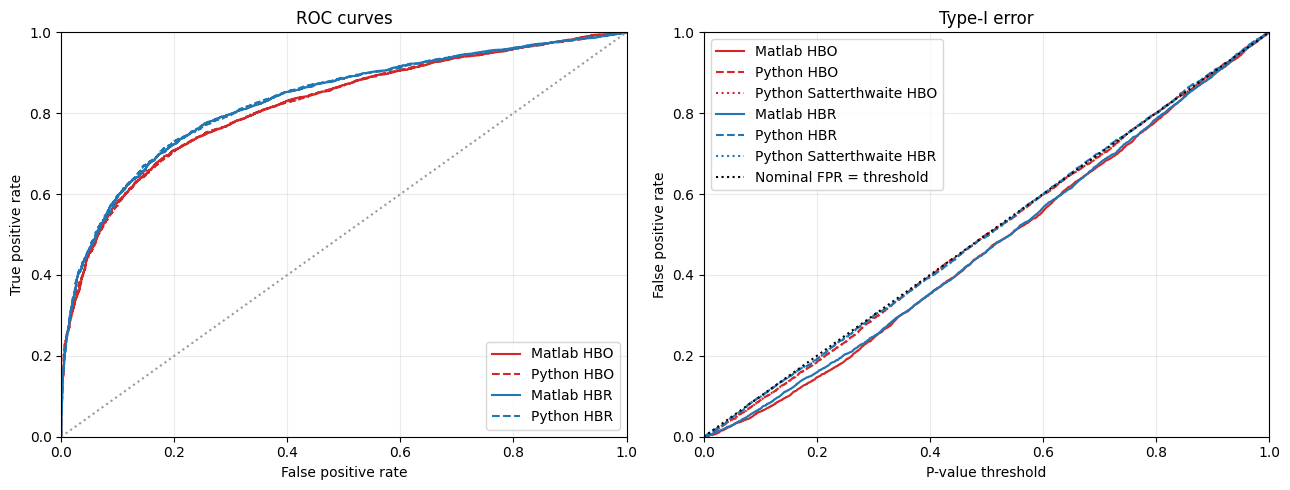

In [2]:
num_iterations = 500
seed = 13
matlab_executable = os.environ.get("PYBRAIN_MATLAB_EXECUTABLE") or None
output_root = repo_root / "matlab-comparison-results"

comparison = run_matlab_python_roc_comparison(
    num_iterations=num_iterations,
    seed=seed,
    output_dir=output_root,
    matlab_executable=matlab_executable,
)

print(f"Saved comparison results to: {comparison.output_dir}")

## Numerical comparison

The metrics below compare matched beta, t-statistic, and p-value estimates.
The type-I error table compares false-positive rates with nominal alpha at
0.01, 0.05, and 0.10. Python Satterthwaite p-values are a diagnostic
alternative only; they do not replace the current GLM p-values.

In [3]:
required_summary_fields = {"degrees_of_freedom", "type_one_error"}
missing_summary_fields = required_summary_fields - comparison.summary.keys()
if missing_summary_fields:
    raise RuntimeError(
        "This comparison result uses an older summary schema. Restart the "
        "kernel and rerun the Configure and run cell before displaying results. "
        f"Missing fields: {sorted(missing_summary_fields)}"
    )

estimate_metrics = pd.DataFrame(comparison.summary["estimate_comparison"]).T
roc_metrics = pd.DataFrame(comparison.summary["roc_comparison"]).T
display(estimate_metrics)
display(roc_metrics)
display(pd.DataFrame(comparison.summary["degrees_of_freedom"]).T)
display(pd.DataFrame.from_dict({
    f"{signal} {method}": metrics["rates"]
    for signal, methods in comparison.summary["type_one_error"].items()
    for method, metrics in methods.items()
}, orient="index").rename_axis("signal / method"))
display(comparison.estimates.head())

,count,mean_absolute_error,max_absolute_error,root_mean_square_error,pearson_correlation
beta,16000.0,0.021736,0.123835,0.028354,0.998027
t_value,16000.0,0.134722,0.771280,0.172187,0.997932
p_value,16000.0,0.037977,0.247201,0.050886,0.989961


,mean_absolute_tpr_difference,max_absolute_tpr_difference
hbo,0.002168,0.03725
hbr,0.002564,0.02350


,median,minimum,maximum
matlab,1148.836718,1127.469921,1163.684492
python_current,1198.000000,1198.000000,1198.000000
python_satterthwaite_candidate,1158.645381,1134.524102,1174.683853


,0.01,0.05,0.1
signal / method,,,
hbo matlab,0.003,0.02800,0.06175
hbo python,0.005,0.04250,0.09050
hbo python_satterthwaite,0.005,0.04250,0.09050
hbr matlab,0.004,0.02775,0.06975
hbr python,0.009,0.04775,0.09850
hbr python_satterthwaite,0.009,0.04775,0.09850


,iteration,source,detector,signal_type,condition,beta_matlab,t_value_matlab,p_value_matlab,dof_matlab,truth_matlab,beta_python,t_value_python,p_value_python,dof_python,dof_satterthwaite_python,p_value_python_satterthwaite
0,1,1,1,hbo,A,0.005413,0.071046,0.943373,1147.449261,0,0.002602,0.059805,0.952321,1198.0,1155.349543,0.952321
1,1,1,1,hbr,A,0.017999,0.531111,0.595445,1147.449261,0,0.011261,0.583834,0.559442,1198.0,1158.388058,0.559446
2,1,2,1,hbo,A,0.040085,0.505471,0.613325,1147.449261,0,0.020641,0.465141,0.641915,1198.0,1162.436228,0.641918
3,1,2,1,hbr,A,-0.017136,-0.455387,0.648917,1147.449261,0,-0.010680,-0.492589,0.622393,1198.0,1163.186574,0.622396
4,1,2,2,hbo,A,0.148822,1.763700,0.078049,1147.449261,1,0.100262,1.969094,0.049173,1198.0,1151.474852,0.049182


## ROC plots

Solid lines show MATLAB, dashed lines show Python, and dotted lines show
Python p-values recalculated with Satterthwaite DOF. Color identifies HbO and
HbR. The type-I error panel includes the nominal diagonal; the generated PNG
and CSV files are also in the saved results folder.

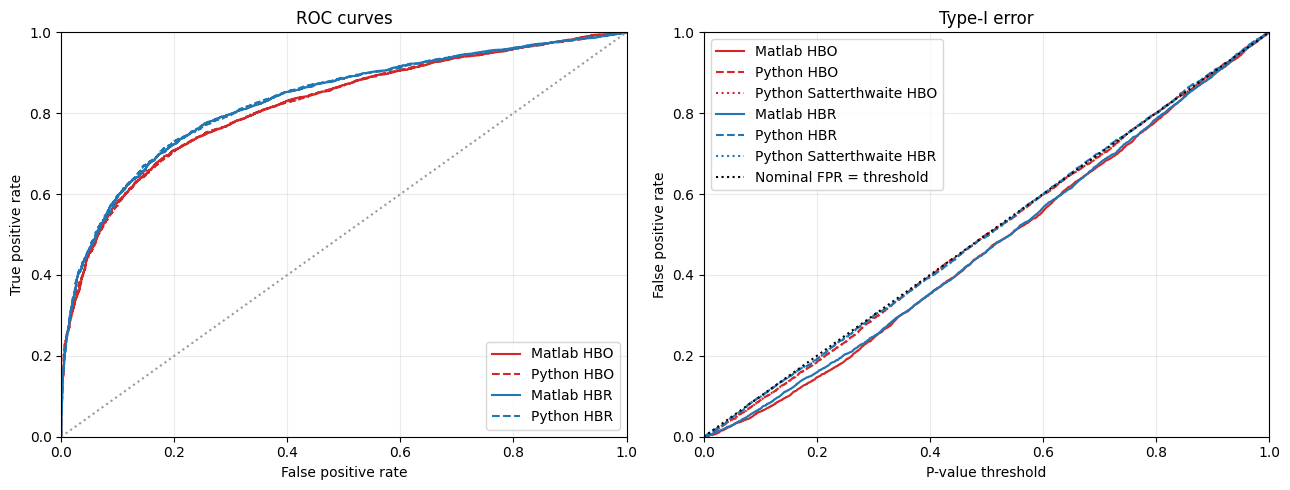

In [4]:
display(comparison.figure)

## Motion-artifact simulation

This run uses MATLAB `nirs.testing.simMotionArtifact` defaults: 2 spikes
per minute and 0.5 shifts per minute. It generates the usual simulated
task data, adds motion artifacts, and retains the original channel truth
labels. All preprocessing, MBLL, resampling, and GLM settings are the same
as in the baseline run above.

Saved motion-artifact results to: /Users/theodorehuppert/VSCode/pyNIRS_toolbox/pyNIRS_toolbox/matlab-comparison-results/matlab-comparison-pi0sl3oa


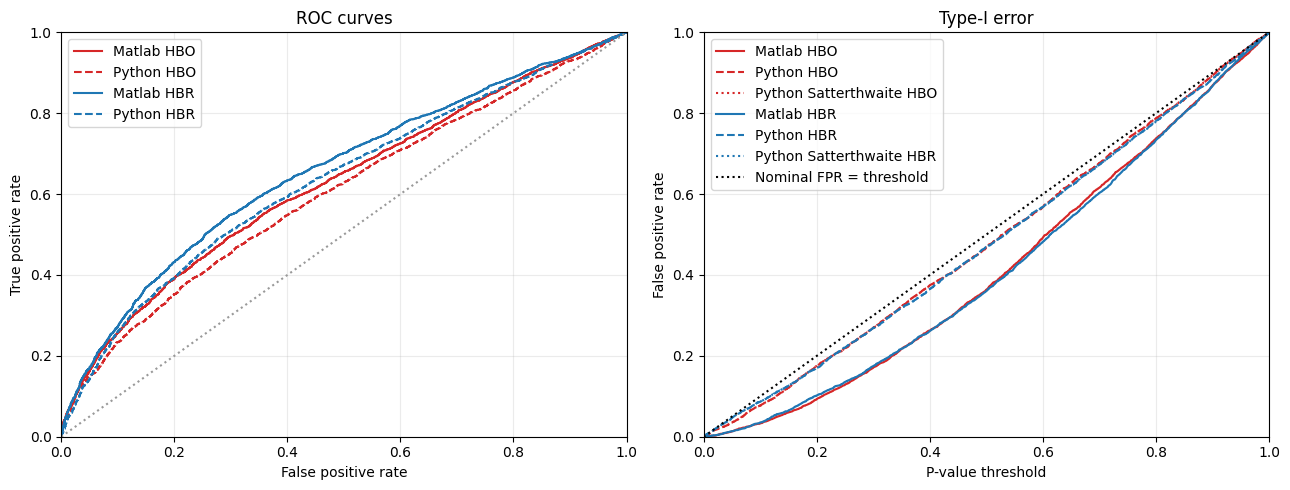

In [5]:
motion_comparison = run_matlab_python_roc_comparison(
    num_iterations=num_iterations,
    seed=seed,
    simulation="simMotionArtifact",
    output_dir=output_root,
    matlab_executable=matlab_executable,
)

print(f"Saved motion-artifact results to: {motion_comparison.output_dir}")

### Motion-artifact comparison results

These metrics compare matched estimates and ROC curves from the two
toolboxes for the motion-contaminated inputs.

In [6]:
required_summary_fields = {"degrees_of_freedom", "type_one_error"}
missing_summary_fields = required_summary_fields - motion_comparison.summary.keys()
if missing_summary_fields:
    raise RuntimeError(
        "This comparison result uses an older summary schema. Restart the "
        "kernel and rerun the motion-artifact comparison cell before displaying "
        f"results. Missing fields: {sorted(missing_summary_fields)}"
    )

motion_estimate_metrics = pd.DataFrame(
    motion_comparison.summary["estimate_comparison"]
).T
motion_roc_metrics = pd.DataFrame(
    motion_comparison.summary["roc_comparison"]
).T
display(motion_estimate_metrics)
display(motion_roc_metrics)
display(pd.DataFrame(motion_comparison.summary["degrees_of_freedom"]).T)
display(pd.DataFrame.from_dict({
    f"{signal} {method}": metrics["rates"]
    for signal, methods in motion_comparison.summary["type_one_error"].items()
    for method, metrics in methods.items()
}, orient="index").rename_axis("signal / method"))
display(motion_comparison.estimates.head())

,count,mean_absolute_error,max_absolute_error,root_mean_square_error,pearson_correlation
beta,16000.0,0.035279,0.306194,0.047568,0.929715
t_value,16000.0,0.325663,1.975771,0.417000,0.936049
p_value,16000.0,0.147339,0.876377,0.195011,0.796579


,mean_absolute_tpr_difference,max_absolute_tpr_difference
hbo,0.023141,0.0450
hbr,0.023153,0.0425


,median,minimum,maximum
matlab,1103.177387,1044.416809,1139.393815
python_current,1198.000000,1198.000000,1198.000000
python_satterthwaite_candidate,1119.566645,979.095053,1155.384574


,0.01,0.05,0.1
signal / method,,,
hbo matlab,0.00125,0.01350,0.03300
hbo python,0.00725,0.03500,0.07725
hbo python_satterthwaite,0.00725,0.03500,0.07725
hbr matlab,0.00150,0.01350,0.03525
hbr python,0.00950,0.04675,0.08675
hbr python_satterthwaite,0.00950,0.04675,0.08675


,iteration,source,detector,signal_type,condition,beta_matlab,t_value_matlab,p_value_matlab,dof_matlab,truth_matlab,beta_python,t_value_python,p_value_python,dof_python,dof_satterthwaite_python,p_value_python_satterthwaite
0,1,1,1,hbo,A,0.024532,0.147197,0.883003,1125.893866,0,0.012469,0.140125,0.888585,1198.0,1112.058420,0.888586
1,1,1,1,hbr,A,0.007968,0.106264,0.915392,1125.893866,0,-0.001788,-0.047567,0.962069,1198.0,1130.289364,0.962070
2,1,2,1,hbo,A,0.047176,0.456671,0.647996,1125.893866,0,0.042685,0.684171,0.493999,1198.0,1133.952745,0.494007
3,1,2,1,hbr,A,-0.038064,-0.527481,0.597964,1125.893866,0,-0.023225,-0.618934,0.536078,1198.0,1110.387117,0.536087
4,1,2,2,hbo,A,0.095983,0.701255,0.483289,1125.893866,1,0.068660,0.860940,0.389443,1198.0,1126.681818,0.389454


### Motion-artifact ROC plots

Solid lines show MATLAB, dashed lines show Python, and dotted lines show
Python p-values recalculated with Satterthwaite DOF. The nominal diagonal
shows expected type-I error. The PNG and CSV files are in the run results folder.

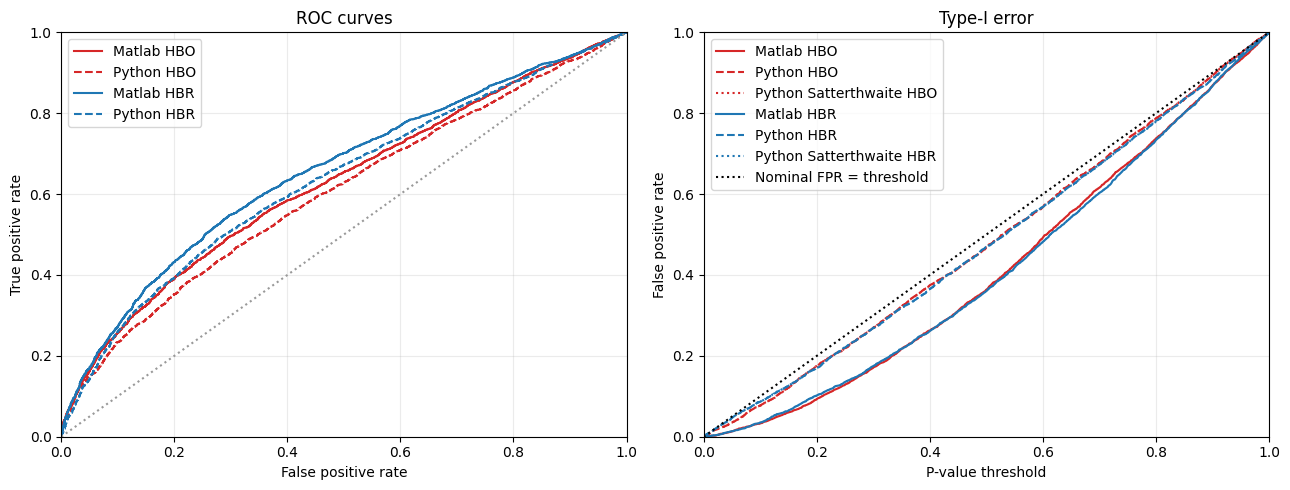

In [7]:
display(motion_comparison.figure)